# 11. Training dan generasi halaman utuh

Loss teacher forcing, raw generation, review manusia dan pemeriksaan browser adalah bukti yang berbeda. Final hanya dibuka setelah kandidat terkunci; notebook pengembangan ini tidak membuka final.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd().resolve()
while not (ROOT / '.venv').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / 'src/fullpage').is_dir(), 'Open using the project kernel and folder'
def read(path): return json.loads((ROOT / path).read_text(encoding='utf-8'))
display(Markdown('Environment proyek: ' + str(ROOT)))

Environment proyek: F:\Generative_AI\Vibe_Coding_Proyek_1

In [2]:
display(read('configs/fullpage/training-v2.json'))
for run in ('TRAIN-016','TRAIN-017'):
    summary = read(f'reports/training/{run}.json')
    display({k:summary.get(k) for k in ('run_id','status','global_step','best_validation_loss','wall_seconds','total_train_tokens','peak_allocated_bytes','free_bytes_after')})

{'mode': 'sft',
 'scope': 'main',
 'data_origin': 'fullpage_curriculum',
 'human_reviewed': False,
 'dataset_dir': 'data/processed/fullpage/v1',
 'seed': 42,
 'block_size': 2048,
 'tokenizer': 'data/tokenizer/tokenizer.json',
 'model_config_path': 'configs/model_fullpage_2048.json',
 'model_config': {'vocab_size': 8192,
  'block_size': 2048,
  'n_layer': 6,
  'n_head': 6,
  'n_embd': 384,
  'dropout': 0.1,
  'tie_embeddings': True,
  'initialization': 'random normal mean 0 std 0.02; no pretrained weights'},
 'device': 'cuda',
 'precision': 'bf16',
 'batch_size': 16,
 'gradient_accumulation': 3,
 'max_steps': 2400,
 'warmup_steps': 120,
 'learning_rate': 5e-05,
 'min_learning_rate': 5e-06,
 'betas': [0.9, 0.95],
 'weight_decay': 0.1,
 'grad_clip': 1,
 'validation_interval': 400,
 'validation_batches': None,
 'checkpoint_interval': 400,
 'log_interval': 100,
 'reserve_free_bytes': 16106127360,
 'initial_checkpoint': 'checkpoints/INIT-2048-001/initial.pt',
 'initial_checkpoint_sha256': '2

{'run_id': 'TRAIN-016',
 'status': 'completed',
 'global_step': 600,
 'best_validation_loss': 0.15091309064510763,
 'wall_seconds': 124.5807515999768,
 'total_train_tokens': 7462133,
 'peak_allocated_bytes': 3726565376,
 'free_bytes_after': 18254815232}

{'run_id': 'TRAIN-017',
 'status': 'completed',
 'global_step': 2400,
 'best_validation_loss': 0.03529969240542512,
 'wall_seconds': 458.47838640003465,
 'total_train_tokens': 29930463,
 'peak_allocated_bytes': 3732061184,
 'free_bytes_after': 17784012800}

## Kurva dan throughput aktual

Training utama berdiri sendiri dari INIT2048, budget2.400. Best dipilih dengan ordinary CE penuh pada development. Best disimpan weights-only; exact resume memakai last.

TRAIN-016 target tokens: 7462133 long-position labels: 3428736 mean target tokens/s: 67583
TRAIN-017 target tokens: 29930463 long-position labels: 13637808 mean target tokens/s: 68321


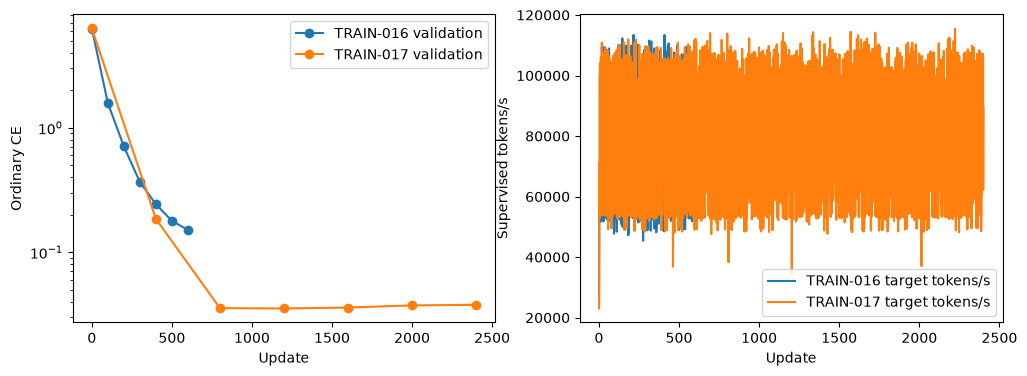

In [3]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
for run in ('TRAIN-016','TRAIN-017'):
    metrics = pd.read_json(ROOT / f'outputs/metrics/{run}.jsonl',lines=True)
    train = metrics[metrics.event=='train']; val = metrics[metrics.event=='validation']
    axes[0].plot(val.step,val.loss,'o-',label=run+' validation')
    axes[1].plot(train.step,train.tokens_per_second,label=run+' target tokens/s')
    print(run, 'target tokens:',int(train.valid_tokens.sum()),'long-position labels:',int(train.supervised_tokens_after_position_1024.sum()),'mean target tokens/s:',int(train.valid_tokens.sum()/train.seconds.sum()))
axes[0].set(xlabel='Update',ylabel='Ordinary CE',yscale='log'); axes[1].set(xlabel='Update',ylabel='Supervised tokens/s')
for ax in axes: ax.legend()
plt.show()

In [4]:
for run in ('TRAIN-016','TRAIN-017'):
    gpu = pd.read_json(ROOT / f'outputs/metrics/{run}_gpu.jsonl',lines=True)
    display(gpu[['utilization_pct','memory_used_mib','power_w','temperature_c']].agg(['mean','max']))
    task_report = ROOT / f'reports/training/{run}_TASK_LOSS.json'
    if task_report.exists(): display(read(str(task_report.relative_to(ROOT))))

,utilization_pct,memory_used_mib,power_w,temperature_c
mean,82.148649,6960.747748,181.13982,60.175676
max,99.000000,7139.000000,200.49000,65.000000


{'checkpoint_sha256': '5386787f5a93b2be7911f3ef1c36a23a80e907f752d359ccf2ba900326b54f87',
 'scope': 'pilot',
 'step': 600,
 'ordinary_ce_by_task': {'page_plan': {'loss': 0.2652617931484201,
   'valid_tokens': 16132,
   'rows': 40,
   'tokens_after_position_1024': 16132,
   'loss_after_position_1024': 0.2652617931484201},
  'section_content': {'loss': 0.10851461514508647,
   'valid_tokens': 43508,
   'rows': 200,
   'tokens_after_position_1024': 0,
   'loss_after_position_1024': None}},
 'selected_vs_full_projection_max_abs_difference': 0,
 'projection_ce_equivalent_within_1e_3_per_token': True,
 'final_data_opened': False,
 'disk_free_bytes': 18254798848}

,utilization_pct,memory_used_mib,power_w,temperature_c
mean,88.47555,6949.783619,194.133178,64.228606
max,99.00000,7042.000000,212.030000,69.000000


{'checkpoint_sha256': 'a0e8137d08ec081a129d6bb977b159b84d31613dcc8e444cc8ea0fe6735074ff',
 'scope': 'main',
 'step': 1200,
 'ordinary_ce_by_task': {'page_plan': {'loss': 0.12299359542599976,
   'valid_tokens': 64572,
   'rows': 160,
   'tokens_after_position_1024': 64572,
   'loss_after_position_1024': 0.12299359542599976},
  'section_content': {'loss': 0.002802872869855533,
   'valid_tokens': 174250,
   'rows': 800,
   'tokens_after_position_1024': 0,
   'loss_after_position_1024': None}},
 'selected_vs_full_projection_max_abs_difference': 0,
 'projection_ce_equivalent_within_1e_3_per_token': True,
 'final_data_opened': False,
 'disk_free_bytes': 17784012800}

## Koreksi review V2

Dua hero pada BEST memakai nama usaha terpotong. Hasil awal41/80 bukan acceptance saat ini. Validasi ulang raw bytes menghasilkan39/80 best dan58/80 last tanpa retraining. Report V2 dan gallery V2 menjadi bukti terkini. Semua fakta terstruktur harus diberikan di request, termasuk demo fiktif. Pemeriksaan ini tidak memverifikasi seluruh klaim pemasaran. Final tetap tertutup dan review browser/manusia pending.

## Generation pilot dan development

Plan512, section1536; output yang tidak valid gagal, tidak diperbaiki memakai target. Retry maksimum sekali. Halaman diterima hanya jika semua fakta dan komponen lolos.

In [5]:
for filename in ('TRAIN-016_PILOT.json','TRAIN-017_DEVELOPMENT_BEST_V2.json','TRAIN-017_DEVELOPMENT_LAST_V2.json'):
    path = ROOT / 'reports/fullpage' / filename
    if path.exists():
        report = read(str(path.relative_to(ROOT)))
        display({k:report.get(k) for k in ('scope','complete','total','first_attempt_complete','after_retry_complete','model_gate','groups','failures','page_seconds','browser_status','human_review_status')})

{'scope': 'pilot',
 'complete': 0,
 'total': 20,
 'first_attempt_complete': 0,
 'after_retry_complete': 0,
 'model_gate': False,
 'groups': {'landing_page:plain_css': {'total': 5,
   'complete': 0,
   'first_attempt': 0},
  'landing_page:tailwind': {'total': 5, 'complete': 0, 'first_attempt': 0},
  'company_profile:plain_css': {'total': 5, 'complete': 0, 'first_attempt': 0},
  'company_profile:tailwind': {'total': 5, 'complete': 0, 'first_attempt': 0}},
 'failures': {'Invalid JSON/contract': 20},
 'page_seconds': {'total': 54.801074699964374, 'mean': 2.740053734998219},
 'browser_status': 'pending',
 'human_review_status': 'pending'}

{'scope': 'development',
 'complete': 39,
 'total': 80,
 'first_attempt_complete': 33,
 'after_retry_complete': 39,
 'model_gate': False,
 'groups': {'landing_page:plain_css': {'total': 20,
   'complete': 10,
   'first_attempt': 10},
  'landing_page:tailwind': {'total': 20, 'complete': 10, 'first_attempt': 10},
  'company_profile:plain_css': {'total': 20,
   'complete': 10,
   'first_attempt': 6},
  'company_profile:tailwind': {'total': 20,
   'complete': 9,
   'first_attempt': 7}},
 'failures': {'plan': 57,
  'section': 2,
  'Unplanned media asset': 6,
  'Required fact text mismatch': 4,
  'Plan request identity/style mismatch': 8,
  'Section descriptor identity mismatch': 2,
  'review_v2_fact_validation': 2},
 'page_seconds': {'total': 567.0923231999041, 'mean': 7.088654039998801},
 'browser_status': 'pending',
 'human_review_status': 'pending'}

{'scope': 'development',
 'complete': 58,
 'total': 80,
 'first_attempt_complete': 51,
 'after_retry_complete': 58,
 'model_gate': False,
 'groups': {'landing_page:plain_css': {'total': 20,
   'complete': 12,
   'first_attempt': 11},
  'landing_page:tailwind': {'total': 20, 'complete': 17, 'first_attempt': 17},
  'company_profile:plain_css': {'total': 20,
   'complete': 14,
   'first_attempt': 13},
  'company_profile:tailwind': {'total': 20,
   'complete': 15,
   'first_attempt': 10}},
 'failures': {'plan': 33,
  'Plan request identity/style mismatch': 10,
  'Required fact text mismatch': 1},
 'page_seconds': {'total': 643.8835040001431, 'mean': 8.04854380000179},
 'browser_status': 'pending',
 'human_review_status': 'pending'}

In [6]:
directory = ROOT / 'outputs/fullpage/TRAIN-017-development-best'
if directory.exists():
    paths = sorted(directory.glob('*/attempt-*/result.json'))
    validated = read('reports/fullpage/TRAIN-017_DEVELOPMENT_BEST_V2.json')
    accepted_ids = {r['request_id'] for r in validated['results'] if r['status']=='accepted'}
    accepted = [p for p in paths if json.loads(p.read_text(encoding='utf-8'))['request_id'] in accepted_ids]
    selected = accepted[0] if accepted else paths[0]
    result = json.loads(selected.read_text(encoding='utf-8'))
    print('Raw model example:',result['request_id'],result['status'])
    display(pd.DataFrame([{k:a.get(k) for k in ('stage','retry','stop_reason','generated_tokens','prefix_tokens','seconds','errors')} for a in result['attempts']]))
    print('Raw plan:',result['attempts'][0].get('raw','')[:1800])
    plan_path = selected.parent / 'plan.json'
    if plan_path.exists(): display(json.loads(plan_path.read_text(encoding='utf-8')))
    website = selected.parent / 'website/page_spec.json'
    if website.exists(): display(json.loads(website.read_text(encoding='utf-8')))

Raw model example: page0240-tailwind accepted


,stage,retry,stop_reason,generated_tokens,prefix_tokens,seconds,errors
0,plan,False,eos,404,1383,1.682691,[]
1,nav,False,eos,128,205,0.569492,[]
2,main,False,eos,186,209,0.777136,[]
3,about,False,eos,160,210,0.668360,[]
4,services,False,eos,345,467,1.465510,[]
5,benefits,False,eos,198,172,0.830644,[]
6,process,False,eos,300,421,1.275478,[]
7,faq,False,eos,336,445,1.349486,[]
8,contact,False,eos,169,93,0.754878,[]
9,footer,False,eos,106,205,0.460174,[]


Raw plan: {"genre":"landing_page","language":"id","schema_version":"1.0","sections":[["nav","navbar","navigation","inline",["name"],[]],["main","hero","hero","split",["name"],["studio-shapes"]],["about","text_section","about","prose",["about"],[]],["services","feature_grid","services","cards",["srv0","srv1","srv2"],[]],["benefits","feature_grid","benefits","cards",["values"],[]],["process","feature_grid","process","numbered",["step0","step1","step2"],[]],["faq","feature_grid","faq","cards",["faq0","faq1","faq2"],[]],["contact","contact_form","contact","panel",[],[]],["footer","footer","footer","columns",["name"],[]]],"style_mode":"tailwind","theme":{"background":"#ffffff","font":"sans","primary":"#2563eb","text":"#111827"},"title":"Studio Wiritana"}


{'genre': 'landing_page',
 'language': 'id',
 'schema_version': '1.0',
 'sections': [{'id': 'nav',
   'type': 'navbar',
   'role': 'navigation',
   'variant': 'inline',
   'fact_ids': ['name'],
   'asset_ids': []},
  {'id': 'main',
   'type': 'hero',
   'role': 'hero',
   'variant': 'split',
   'fact_ids': ['name'],
   'asset_ids': ['studio-shapes']},
  {'id': 'about',
   'type': 'text_section',
   'role': 'about',
   'variant': 'prose',
   'fact_ids': ['about'],
   'asset_ids': []},
  {'id': 'services',
   'type': 'feature_grid',
   'role': 'services',
   'variant': 'cards',
   'fact_ids': ['srv0', 'srv1', 'srv2'],
   'asset_ids': []},
  {'id': 'benefits',
   'type': 'feature_grid',
   'role': 'benefits',
   'variant': 'cards',
   'fact_ids': ['values'],
   'asset_ids': []},
  {'id': 'process',
   'type': 'feature_grid',
   'role': 'process',
   'variant': 'numbered',
   'fact_ids': ['step0', 'step1', 'step2'],
   'asset_ids': []},
  {'id': 'faq',
   'type': 'feature_grid',
   'role':

{'schema_version': '2.0',
 'genre': 'landing_page',
 'title': 'Studio Wiritana',
 'language': 'id',
 'style_mode': 'tailwind',
 'theme': {'background': '#ffffff',
  'font': 'sans',
  'primary': '#2563eb',
  'text': '#111827'},
 'sections': [{'id': 'nav',
   'props': {'brand': 'Studio Wiritana',
    'links': [{'href': '#about', 'label': 'Tentang'},
     {'href': '#services', 'label': 'Layanan'},
     {'href': '#contact', 'label': 'Kontak'}]},
   'role': 'navigation',
   'type': 'navbar',
   'variant': 'inline'},
  {'id': 'main',
   'props': {'button': {'href': '#contact', 'label': 'Diskusikan kebutuhan'},
    'heading': 'Studio Wiritana',
    'layout': 'split',
    'media': {'alt': 'Ilustrasi usaha demo fiktif',
     'asset_id': 'studio-shapes'},
    'text': 'Kenali layanan desain dan komunikasi dan diskusikan kebutuhan Anda. Demo fiktif.'},
   'role': 'hero',
   'type': 'hero',
   'variant': 'split'},
  {'id': 'about',
   'props': {'heading': 'Tentang Studio Wiritana',
    'text': 'Stu

In [7]:
display(Markdown('[Gallery best V2](../examples/generated/AI-018-best-v2/index.html) | [Gallery last V2](../examples/generated/AI-018-last-v2/index.html)'))
review = read('reports/fullpage/AI-018_REVIEW_AFTER.json')
display(pd.DataFrame([{'case':c['case'],'rejected':c['rejected']} for c in review['checks']]))
print('Final dibuka:',review['final_data_opened'])

[Gallery best V2](../examples/generated/AI-018-best-v2/index.html) | [Gallery last V2](../examples/generated/AI-018-last-v2/index.html)

,case,rejected
0,saved_truncated_hero_name,True
1,extra_services_fictitious_False,True
2,extra_portfolio_fictitious_False,True
3,unprovided_testimonial_fictitious_False,True
4,extra_services_fictitious_True,True
5,extra_portfolio_fictitious_True,True
6,unprovided_testimonial_fictitious_True,True
7,single_final_identity_and_matching_resume,True


Final dibuka: False


## Status akhir dan opt-in training

UI tetap tahap akhir. Jangan menyatakan model siap jika gate development belum95%, review manusia belum diisi, atau browser belum diperiksa. Sel di bawah tidak memulai training ketika notebook dibuka.

In [8]:
progress = ROOT / 'reports/fullpage/AI-018_PROGRESS.json'
if progress.exists():
    snapshot = read(str(progress.relative_to(ROOT)))
    display({k:v for k,v in snapshot.items() if k!='evidence'})
RUN_TRAINING = False
if RUN_TRAINING:
    raise RuntimeError('Create a new logged run ID or exact-resume from last; preserve previous artifacts. Use qa.run_logged and qa.train_fullpage.')
print('Training automatic execution:',RUN_TRAINING)

{'status': 'needs_more_model_work',
 'final_evaluated': False,
 'human_review_status': 'pending',
 'browser_status': 'pending',
 'ui_implemented': False,
 'limits': ['Synthetic four-sector curriculum, not arbitrary web instructions.',
  'Shared component text and templates intentionally repeated.',
  'Heldout target order is disclosed but request acceptance allows any valid required-role order.',
  'No human ratings or browser acceptance are invented.']}

Training automatic execution: False
